In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import seaborn as sns


In [3]:
from pathlib import Path
path = next(p for p in [Path("../DATA/European_Bank.csv"), Path("DATA/European_Bank.csv")] if p.exists())
DF = pd.read_csv(path)
print("dataset loaded successfully")

dataset loaded successfully


In [4]:
DF.head()


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
DF.shape

(10000, 14)

In [6]:
DF.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [7]:
DF.isnull().sum()

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
print(DF['Exited'].unique())
print(DF['HasCrCard'].unique())
print(DF['IsActiveMember'].unique())

[1 0]
[1 0]
[1 0]


In [9]:
DF.drop(['CustomerId', 'Surname', 'Year'], axis=1, inplace=True)
print("Columns dropped successfully!")
print(DF.shape)

Columns dropped successfully!
(10000, 11)


In [10]:
DF. columns


Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='str')

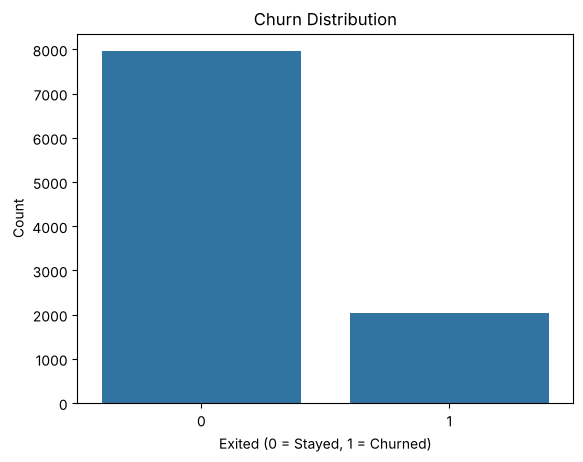

In [11]:
#Churn Distribution
sns.countplot(x="Exited", data=DF)
plt.title("Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Count")
plt.show()


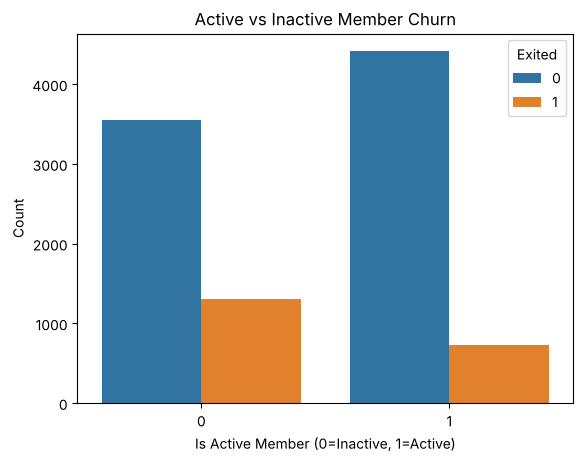

In [12]:
# Engagement vs Churn
sns.countplot(x='IsActiveMember', hue='Exited', data=DF)
plt.title('Active vs Inactive Member Churn')
plt.xlabel('Is Active Member (0=Inactive, 1=Active)')
plt.ylabel('Count')
plt.show()

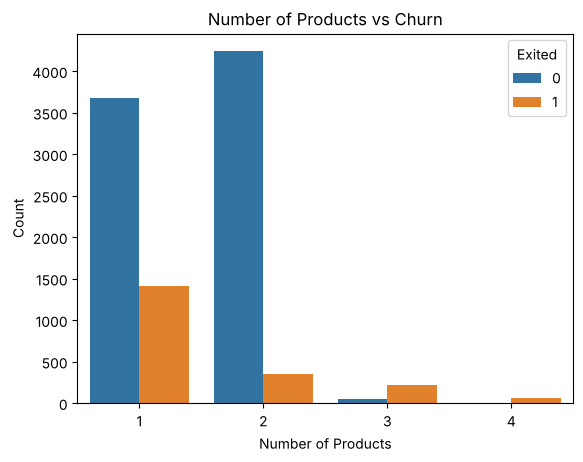

In [13]:
# Products vs Churn
sns.countplot(x='NumOfProducts', hue='Exited', data=DF)
plt.title('Number of Products vs Churn')
plt.xlabel('Number of Products')
plt.ylabel('Count')
plt.show()

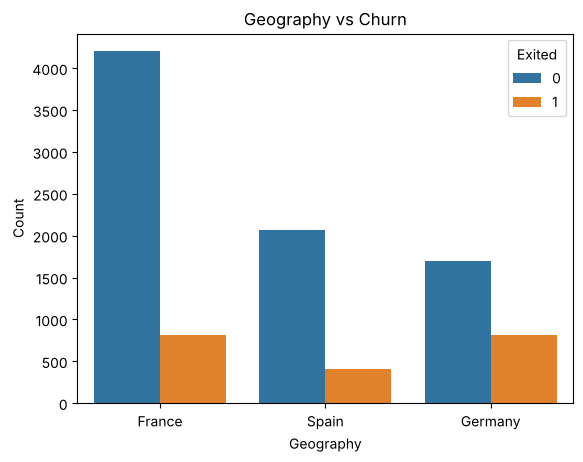

In [14]:
# Geography vs Churn
sns.countplot(x='Geography', hue='Exited', data=DF)
plt.title('Geography vs Churn')
plt.xlabel('Geography')
plt.ylabel('Count')
plt.show()

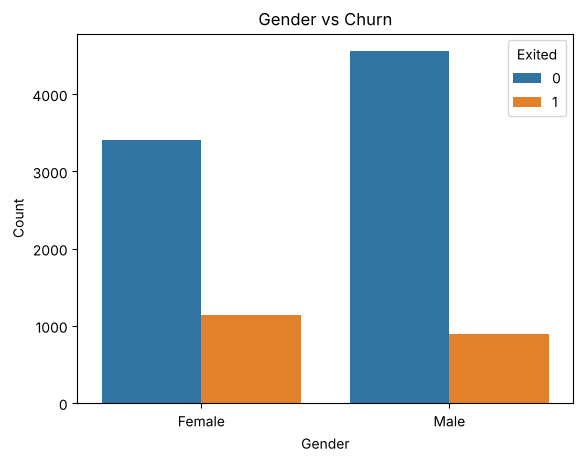

In [15]:
#Gender vs Churn
sns.countplot(x='Gender', hue='Exited', data=DF)
plt.title('Gender vs Churn')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

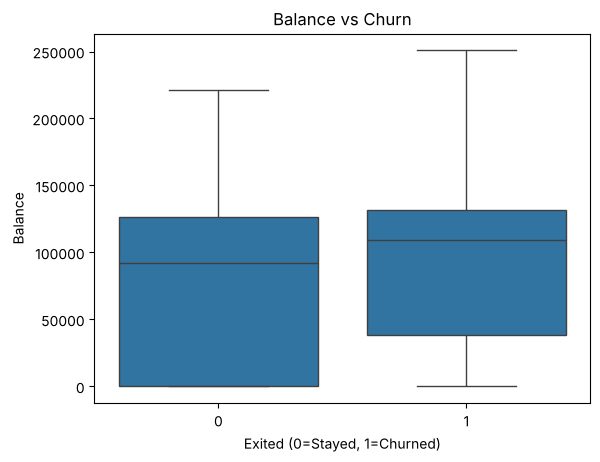

In [16]:
# Balance vs Churn
sns.boxplot(x='Exited', y='Balance', data=DF)
plt.title('Balance vs Churn')
plt.xlabel('Exited (0=Stayed, 1=Churned)')
plt.ylabel('Balance')
plt.show()

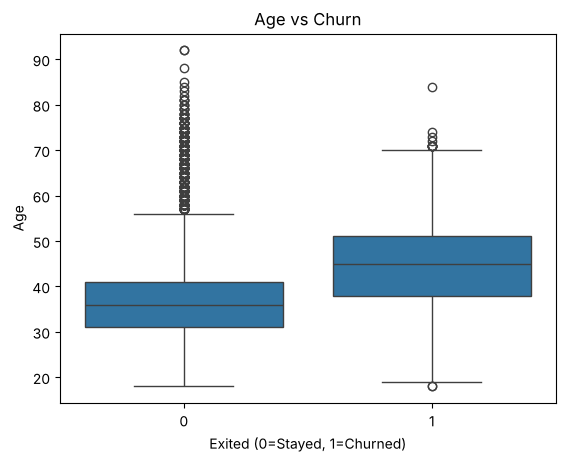

In [17]:
#Age vs Churn
sns.boxplot(x='Exited', y='Age', data=DF)
plt.title('Age vs Churn')
plt.xlabel('Exited (0=Stayed, 1=Churned)')
plt.ylabel('Age')
plt.show()

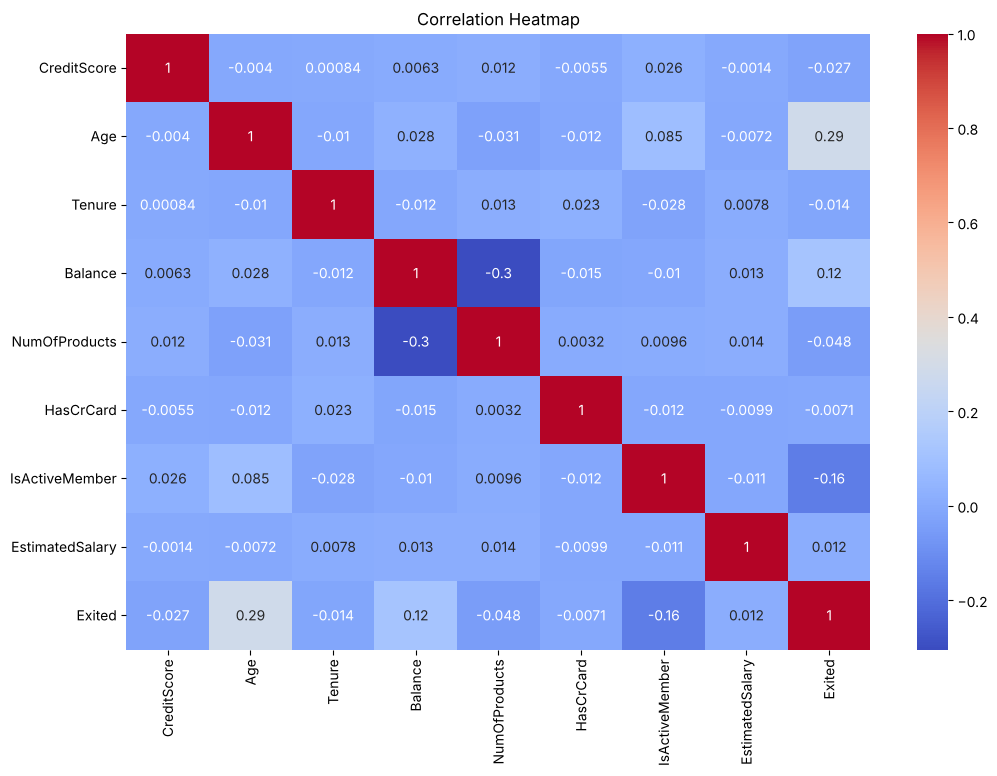

In [18]:
#Correlation Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(DF.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [19]:
# Feature Engineering
# Create Engagement Profile
def engagement_profile(row):
    if row['IsActiveMember'] == 1 and row['NumOfProducts'] >= 2:
        return 'Highly Engaged'
    elif row['IsActiveMember'] == 0 and row['Balance'] > 100000:
        return 'High Value Disengaged'
    elif row['IsActiveMember'] == 1 and row['NumOfProducts'] == 1:
        return 'Active Low Product'
    else:
        return 'Inactive Low Engagement'

DF['EngagementProfile'] = DF.apply(engagement_profile, axis=1)
print("Done!")
print(DF['EngagementProfile'].value_counts())

Done!
EngagementProfile
Highly Engaged             2588
Active Low Product         2563
Inactive Low Engagement    2493
High Value Disengaged      2356
Name: count, dtype: int64


In [20]:
#Create Relationship Score
DF['RelationshipScore'] = (
    DF['IsActiveMember'] * 40 +
    DF['NumOfProducts'] * 20 +
    DF['HasCrCard'] * 10
)
print(DF['RelationshipScore'].value_counts())

RelationshipScore
70     1887
30     1803
90     1757
50     1511
60      829
80      720
20      718
40      633
110      78
100      35
130      19
120      10
Name: count, dtype: int64


In [21]:
# Create Premium At Risk Flag
DF['PremiumAtRisk'] = (
    (DF['Balance'] > 100000) & 
    (DF['IsActiveMember'] == 0)
).astype(int)

print(DF['PremiumAtRisk'].value_counts())

PremiumAtRisk
0    7644
1    2356
Name: count, dtype: int64


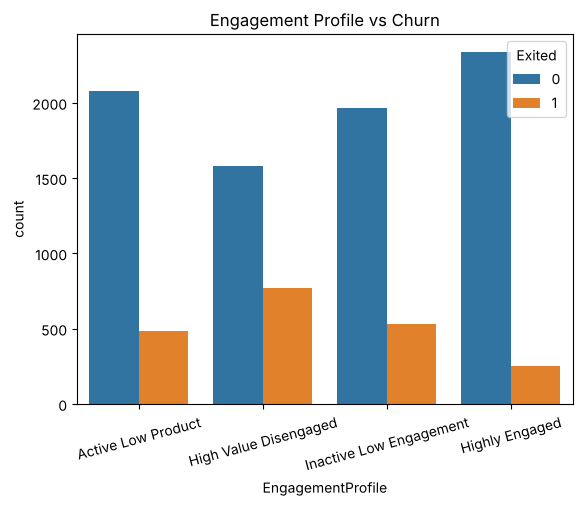

In [22]:
#Visualise Engagement Profile vs Churn
sns.countplot(x='EngagementProfile', hue='Exited', data=DF)
plt.title('Engagement Profile vs Churn')
plt.xticks(rotation=15)
plt.show()

In [23]:
# KPI 1: Engagement Retention Ratio
active_churn = DF[DF['IsActiveMember']==1]['Exited'].mean()
inactive_churn = DF[DF['IsActiveMember']==0]['Exited'].mean()

print(f"Active Member Churn Rate: {active_churn*100:.2f}%")
print(f"Inactive Member Churn Rate: {inactive_churn*100:.2f}%")
print(f"Inactive members are {inactive_churn/active_churn:.2f}x more likely to churn")

Active Member Churn Rate: 14.27%
Inactive Member Churn Rate: 26.85%
Inactive members are 1.88x more likely to churn


In [24]:
# KPI 2: Product Depth Index
product_churn = DF.groupby('NumOfProducts')['Exited'].mean()*100
print("Churn Rate by Number of Products:")
print(product_churn.round(2))

Churn Rate by Number of Products:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64


In [25]:
# KPI 3: High Balance Disengagement Rate
high_balance = DF[DF['Balance'] > 100000]
rate = high_balance[high_balance['IsActiveMember']==0]['Exited'].mean()
print(f"High Balance Disengagement Churn Rate: {rate*100:.2f}%")

High Balance Disengagement Churn Rate: 32.77%


In [26]:
# KPI 4: Credit Card Stickiness
card_churn = DF.groupby('HasCrCard')['Exited'].mean()*100
print("Churn Rate by Credit Card Ownership:")
print(card_churn.round(2))

Churn Rate by Credit Card Ownership:
HasCrCard
0    20.81
1    20.18
Name: Exited, dtype: float64


In [27]:
#KPI 5: Relationship Strength Index
relationship = DF.groupby('RelationshipScore')['Exited'].mean()*100
print("Churn Rate by Relationship Score:")
print(relationship.round(2))

Churn Rate by Relationship Score:
RelationshipScore
20      34.54
30      37.49
40      10.43
50       9.66
60      24.97
70      21.89
80       7.64
90       6.37
100     77.14
110     74.36
120    100.00
130    100.00
Name: Exited, dtype: float64


In [28]:
# Premium At Risk Summary
premium_risk = DF[
    (DF['Balance'] > 100000) &
    (DF['IsActiveMember'] == 0) &
    (DF['Exited'] == 1)
]
print(f"Total Premium At Risk Customers who churned: {len(premium_risk)}")
print(premium_risk[['Age', 'Balance', 'NumOfProducts', 'Geography']].describe())

Total Premium At Risk Customers who churned: 772


              Age        Balance  NumOfProducts
count  772.000000     772.000000     772.000000
mean    44.496114  131656.599870       1.432642
std      9.783187   22639.163127       0.780350
min     20.000000  100032.520000       1.000000
25%     38.000000  114590.970000       1.000000
50%     45.000000  127207.160000       1.000000
75%     51.000000  144509.610000       2.000000
max     72.000000  222267.630000       4.000000


# Extended Analysis: Engagement, Product Depth and Retention Strength
This section extends the EDA and KPI cells above with the remaining items from the project brief:
data-quality table, balance vs activity, salary–balance mismatch, Product Depth Index,
Credit Card Stickiness Score, Relationship Strength Index (RSI), sticky customers,
engagement thresholds and churn stability.

## E0. Setup

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

path = next(p for p in [Path("../DATA/European_Bank.csv"), Path("DATA/European_Bank.csv")] if p.exists())
raw = pd.read_csv(path)
df = raw.drop(columns=["Surname", "Year"], errors="ignore").copy()

HV = 100_000        # high-value balance threshold (same as the paper and the app)
SAL_HI = 150_000    # high-salary threshold
RATIO_HI = 3.0      # balance-to-salary ratio flag
overall = df["Exited"].mean()
print(f"{len(df):,} customers | overall churn {overall:.2%}")

10,000 customers | overall churn 20.37%


## E1. Data validation table (for the paper's 'Data Quality' section)

In [30]:
def status(ok): return "Pass" if ok else "Fail"

quality = pd.DataFrame([
    ("Rows x columns", f"{raw.shape[0]:,} x {raw.shape[1]}", "Info"),
    ("Missing values", int(raw.isna().sum().sum()), status(raw.isna().sum().sum() == 0)),
    ("Duplicate CustomerId", int(raw["CustomerId"].duplicated().sum()), status(not raw["CustomerId"].duplicated().any())),
    ("HasCrCard only 0/1", int((~raw["HasCrCard"].isin([0, 1])).sum()), status(raw["HasCrCard"].isin([0, 1]).all())),
    ("IsActiveMember only 0/1", int((~raw["IsActiveMember"].isin([0, 1])).sum()), status(raw["IsActiveMember"].isin([0, 1]).all())),
    ("Exited only 0/1", int((~raw["Exited"].isin([0, 1])).sum()), status(raw["Exited"].isin([0, 1]).all())),
    ("NumOfProducts within 1-4", f"{raw['NumOfProducts'].min()} to {raw['NumOfProducts'].max()}", status(raw["NumOfProducts"].between(1, 4).all())),
    ("Balance not negative", f"min {raw['Balance'].min():,.2f}", status((raw["Balance"] >= 0).all())),
    ("Age positive", f"min {raw['Age'].min()}", status((raw["Age"] > 0).all())),
    ("Overall churn rate", f"{raw['Exited'].mean():.2%}", "Info"),
], columns=["Check", "Result", "Status"])
quality

,Check,Result,Status
0,Rows x columns,"10,000 x 14",Info
1,Missing values,0,Pass
2,Duplicate CustomerId,0,Pass
3,HasCrCard only 0/1,0,Pass
4,IsActiveMember only 0/1,0,Pass
5,Exited only 0/1,0,Pass
6,NumOfProducts within 1-4,1 to 4,Pass
7,Balance not negative,min 0.00,Pass
8,Age positive,min 18,Pass
9,Overall churn rate,20.37%,Info


## E2. Product utilization

,Customers,Churn rate (%),Retention rate (%)
NumOfProducts,,,
1,5084,27.71,72.29
2,4590,7.58,92.42
3,266,82.71,17.29
4,60,100.00,0.00


,Customers,Churn rate (%)
ProductGroup,,
1 product,5084,27.71
2 products,4590,7.58
3-4 products,326,85.89


Pearson corr (NumOfProducts, Exited): -0.048


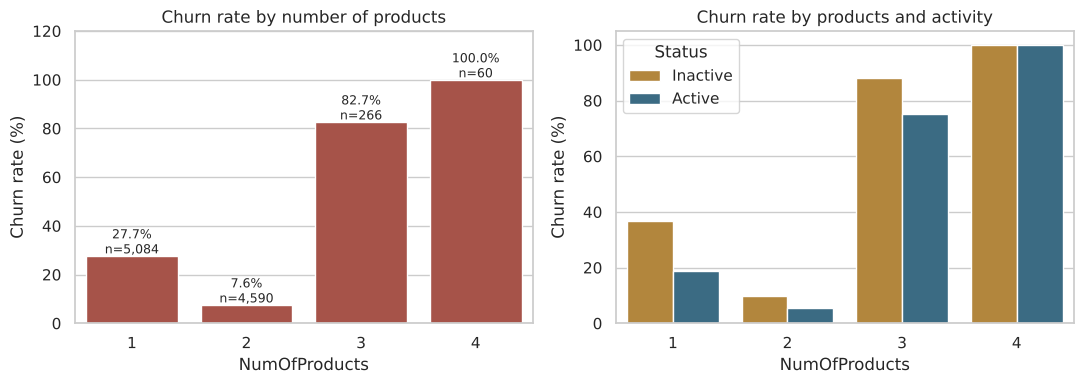

In [31]:
by_products = df.groupby("NumOfProducts")["Exited"].agg(Customers="size", Churn="mean")
by_products["Churn rate (%)"] = by_products["Churn"] * 100
by_products["Retention rate (%)"] = 100 - by_products["Churn rate (%)"]
display(by_products.drop(columns="Churn"))

df["ProductGroup"] = pd.cut(df.NumOfProducts, [0, 1, 2, 4], labels=["1 product", "2 products", "3-4 products"])
group = df.groupby("ProductGroup", observed=True)["Exited"].agg(Customers="size", Churn="mean")
group["Churn rate (%)"] = group["Churn"] * 100
display(group.drop(columns="Churn"))

# Is the relationship linear? Correlation says yes-ish, the table says no.
print("Pearson corr (NumOfProducts, Exited):", round(df.NumOfProducts.corr(df.Exited), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=by_products.index, y=by_products["Churn rate (%)"], color="#B5473A", ax=ax[0])
ax[0].set_title("Churn rate by number of products")
for i, (n, r) in enumerate(zip(by_products.Customers, by_products["Churn rate (%)"])):
    ax[0].text(i, r + 1, f"{r:.1f}%\nn={n:,}", ha="center", fontsize=9)
ax[0].set_ylim(0, 120)

pa = df.groupby(["NumOfProducts", "IsActiveMember"])["Exited"].mean().mul(100).reset_index()
pa["Status"] = pa.IsActiveMember.map({1: "Active", 0: "Inactive"})
sns.barplot(data=pa, x="NumOfProducts", y="Exited", hue="Status",
            palette={"Active": "#2F6F8F", "Inactive": "#C58B2A"}, ax=ax[1])
ax[1].set_title("Churn rate by products and activity"); ax[1].set_ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()

**Reading this:** 2 products is the sweet spot. Churn jumps for 3 and 4 products, but those groups are small
(266 and 60 customers), so describe them as associated with high churn rather than claiming that
cross-selling causes it.

## E3. Financial commitment vs engagement

,Inactive churn (%),Active churn (%),Inactive customers,Active customers
BalanceBand,,,,
Zero,18.35,9.61,1744,1873
Up to 100k,28.04,13.89,749,835
100k-150k,33.49,18.39,1872,1958
Above 150k,29.96,16.29,484,485


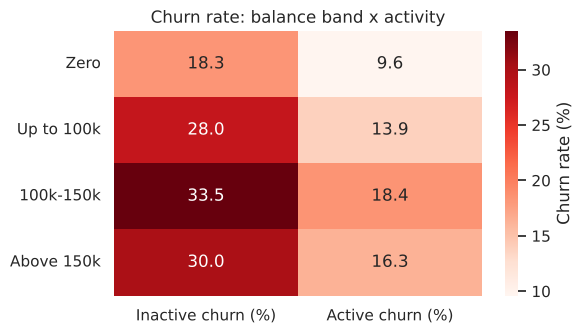

In [32]:
df["BalanceBand"] = pd.cut(df.Balance, [-1, 0, 100_000, 150_000, np.inf],
                           labels=["Zero", "Up to 100k", "100k-150k", "Above 150k"])
churn_ct = pd.crosstab(df.BalanceBand, df.IsActiveMember, values=df.Exited, aggfunc="mean").mul(100)
count_ct = pd.crosstab(df.BalanceBand, df.IsActiveMember)
churn_ct.columns = ["Inactive churn (%)", "Active churn (%)"]
count_ct.columns = ["Inactive customers", "Active customers"]
display(churn_ct.join(count_ct))

plt.figure(figsize=(6, 3.5))
sns.heatmap(churn_ct, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn rate: balance band x activity"); plt.ylabel(""); plt.tight_layout(); plt.show()

In [33]:
# Salary-balance mismatch
df["BalanceSalaryRatio"] = df.Balance / df.EstimatedSalary

flags = pd.DataFrame({
    f"High balance (>{HV:,}) and inactive": (df.Balance > HV) & (df.IsActiveMember == 0),
    f"Balance >= {RATIO_HI:g}x salary and inactive": (df.BalanceSalaryRatio >= RATIO_HI) & (df.IsActiveMember == 0),
    f"Salary >= {SAL_HI:,} but near-empty balance": (df.EstimatedSalary >= SAL_HI) & (df.BalanceSalaryRatio <= 0.05),
})
df["AtRiskFlag"] = flags.any(axis=1)

mismatch = pd.DataFrame({
    "Customers": flags.sum(),
    "Still with bank": [(flags[c] & (df.Exited == 0)).sum() for c in flags],
    "Churn rate (%)": [df.loc[flags[c], "Exited"].mean() * 100 for c in flags],
})
display(mismatch)
print(f"Any flag: {df.AtRiskFlag.sum():,} customers | churn {df.loc[df.AtRiskFlag,'Exited'].mean():.1%} "
      f"vs {df.loc[~df.AtRiskFlag,'Exited'].mean():.1%} for the rest")

,Customers,Still with bank,Churn rate (%)
"High balance (>100,000) and inactive",2356,1584,32.77
Balance >= 3x salary and inactive,590,398,32.54
"Salary >= 150,000 but near-empty balance",874,745,14.76


Any flag: 3,326 customers | churn 28.0% vs 16.6% for the rest


In [34]:
# At-risk premium customers: high balance and inactive
premium = df[(df.Balance > HV) & (df.IsActiveMember == 0)]
rest = df.drop(premium.index)
retained_premium = premium[premium.Exited == 0]

print(f"Premium inactive customers : {len(premium):,}")
print(f"  already churned          : {int(premium.Exited.sum()):,} ({premium.Exited.mean():.1%})")
print(f"  still with the bank      : {len(retained_premium):,}  <- the customers to contact now")
print(f"  balance still at stake   : {retained_premium.Balance.sum()/1e6:,.1f}M")
print(f"Churn rate of all other customers: {rest.Exited.mean():.1%}")

# Export the contact list (CustomerId only, no surname)
retained_premium[["CustomerId", "Geography", "Age", "Balance", "EstimatedSalary", "NumOfProducts"]] \
    .sort_values("Balance", ascending=False).to_csv("at_risk_premium_customers.csv", index=False)

Premium inactive customers : 2,356
  already churned          : 772 (32.8%)
  still with the bank      : 1,584  <- the customers to contact now
  balance still at stake   : 210.6M
Churn rate of all other customers: 16.5%


## E4. KPIs

In [35]:
act, ina = df[df.IsActiveMember == 1], df[df.IsActiveMember == 0]
one, two = df[df.NumOfProducts == 1], df[df.NumOfProducts == 2]
card, nocard = df[df.HasCrCard == 1], df[df.HasCrCard == 0]
hb = df[df.Balance > HV]

kpis = pd.DataFrame([
    ("Engagement Retention Ratio", ina.Exited.mean() / act.Exited.mean(), "x",
     "Churn (inactive) / churn (active)"),
    ("Product Depth Index", (1 - two.Exited.mean()) / (1 - one.Exited.mean()), "x",
     "Retention (2 products) / retention (1 product)"),
    ("High-Balance Disengagement Rate", hb[hb.IsActiveMember == 0].Exited.mean() * 100, "%",
     "Churn rate of inactive customers with balance > threshold"),
    ("High-balance customers who are inactive", (hb.IsActiveMember == 0).mean() * 100, "%",
     "Share of high-balance customers who are inactive"),
    ("Credit Card Stickiness Score", ((1 - card.Exited.mean()) - (1 - nocard.Exited.mean())) * 100, "pp",
     "Retention (card) - retention (no card)"),
], columns=["KPI", "Value", "Unit", "Definition"])
kpis

,KPI,Value,Unit,Definition
0,Engagement Retention Ratio,1.88,x,Churn (inactive) / churn (active)
1,Product Depth Index,1.28,x,Retention (2 products) / retention (1 product)
2,High-Balance Disengagement Rate,32.77,%,Churn rate of inactive customers with balance ...
3,High-balance customers who are inactive,49.09,%,Share of high-balance customers who are inactive
4,Credit Card Stickiness Score,0.63,pp,Retention (card) - retention (no card)


## E5. Relationship Strength Index (RSI), sticky customers and thresholds
RSI (0 to 100) = 40% activity + 30% product count + 20% credit card + 10% tenure.
Products and tenure are min-max scaled. Tiers are tertiles of the full dataset.

In [36]:
mm = lambda s: (s - s.min()) / (s.max() - s.min())
df["RSI"] = (100 * (0.4 * df.IsActiveMember + 0.3 * mm(df.NumOfProducts)
                    + 0.2 * df.HasCrCard + 0.1 * mm(df.Tenure))).round(1)

c1, c2 = df.RSI.quantile([1/3, 2/3]).round(1)
df["RSITier"] = pd.cut(df.RSI, [-np.inf, c1, c2, np.inf], labels=["Low", "Medium", "High"])
print(f"Tier cut-offs: Low <= {c1}, Medium <= {c2}, High > {c2}")

tiers = df.groupby("RSITier", observed=True)["Exited"].agg(Customers="size", Churn="mean")
tiers["Churn rate (%)"] = tiers.Churn * 100
display(tiers.drop(columns="Churn"))

sticky = df[df.RSITier == "High"]
print(f"High-tier customers: {len(sticky):,} ({len(sticky)/len(df):.1%}), churn {sticky.Exited.mean():.1%}")

# The High tier still contains 3-4 product customers, who churn heavily.
# A tighter, more defensible sticky definition: High tier AND at most 2 products.
heavy = sticky[sticky.NumOfProducts >= 3]
sticky_clean = sticky[sticky.NumOfProducts <= 2]
print(f"  of which 3-4 products : {len(heavy):,} customers, churn {heavy.Exited.mean():.1%}")
print(f"Sticky customers (High tier, <=2 products): {len(sticky_clean):,} ({len(sticky_clean)/len(df):.1%}), "
      f"churn {sticky_clean.Exited.mean():.1%}")

Tier cut-offs: Low <= 31.0, Medium <= 62.0, High > 62.0


,Customers,Churn rate (%)
RSITier,,
Low,3370,31.10
Medium,3442,16.39
High,3188,13.33


High-tier customers: 3,188 (31.9%), churn 13.3%
  of which 3-4 products : 137 customers, churn 81.8%
Sticky customers (High tier, <=2 products): 3,051 (30.5%), churn 10.3%


RSITier,Low,Medium,High
Geography,,,
France,24.80,12.60,10.80
Germany,46.10,26.70,22.80
Spain,27.50,14.00,9.30


,RSI >=,Customers,Churn rate (%)
0,0,10000,20.37
1,10,9315,19.30
2,20,8680,19.91
3,30,6897,15.18
4,40,5362,16.08
5,50,4428,13.48
6,60,3683,14.17
7,70,1927,10.07
8,80,187,43.85
9,90,24,100.00


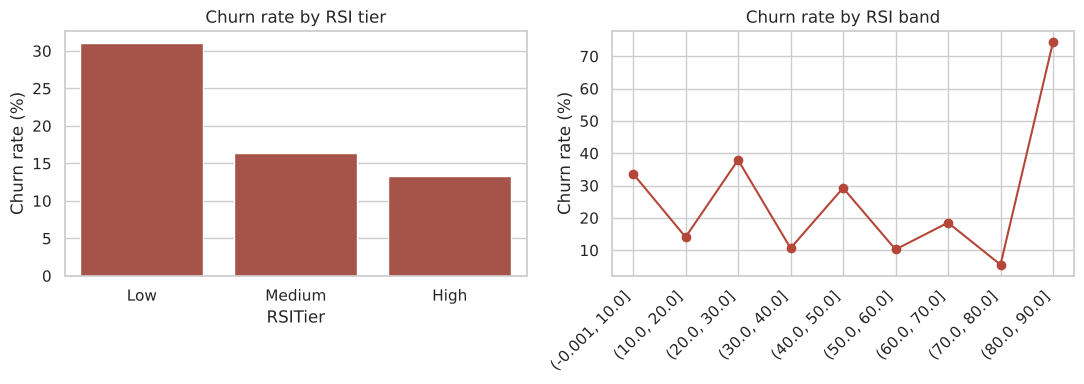

In [37]:
# Churn stability: does the tier ordering hold in every country?
stab = (df.groupby(["Geography", "RSITier"], observed=True)["Exited"].mean().mul(100)
          .unstack("RSITier").round(1))
display(stab)

# Engagement threshold: churn of customers at or above each RSI cut-off
rows = []
for cut in range(0, 100, 10):
    sub = df[df.RSI >= cut]
    rows.append((cut, len(sub), sub.Exited.mean() * 100))
thr = pd.DataFrame(rows, columns=["RSI >=", "Customers", "Churn rate (%)"])
display(thr)

bins = list(range(0, 101, 10))
df["RSIBand"] = pd.cut(df.RSI, bins, include_lowest=True)
band = df.groupby("RSIBand", observed=True)["Exited"].agg(Customers="size", Churn="mean")
band = band[band.Customers >= 30]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=tiers.index, y=tiers["Churn rate (%)"], color="#B5473A", ax=ax[0])
ax[0].set_title("Churn rate by RSI tier")
ax[1].plot(range(len(band)), band.Churn * 100, marker="o", color="#B5473A")
ax[1].set_xticks(range(len(band))); ax[1].set_xticklabels([str(i) for i in band.index], rotation=45, ha="right")
ax[1].set_title("Churn rate by RSI band"); ax[1].set_ylabel("Churn rate (%)")
plt.tight_layout(); plt.show()

**Caveat for the paper:** RSI scores 3 and 4 products higher, yet those customers churn heavily.
That is why the churn rate rises again at RSI 80 and above, and why the sticky definition above
excludes 3-4 product customers. Mention this limitation and keep the product-count analysis
alongside the RSI results.

## E6. Optional: feature importance (backs the 'behaviour vs demographics' claim)
This checks which variables matter most for predicting churn. It shows association, not causation.

Test ROC-AUC: 0.873


,Importance (drop in AUC)
Age,0.13
NumOfProducts,0.12
Balance,0.03
IsActiveMember,0.03
Geography_Germany,0.03
Gender_Male,0.01
CreditScore,0.00
Geography_Spain,-0.00
HasCrCard,-0.00
EstimatedSalary,-0.00


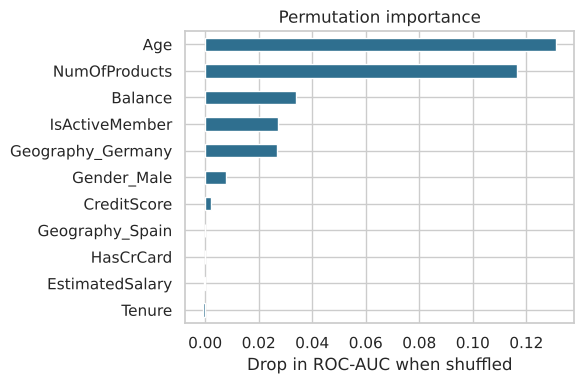

In [38]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard",
            "IsActiveMember", "EstimatedSalary", "Geography", "Gender"]
X = pd.get_dummies(df[features], drop_first=True)
y = df.Exited
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Xtr, ytr)
print("Test ROC-AUC:", round(roc_auc_score(yte, rf.predict_proba(Xte)[:, 1]), 3))

perm = permutation_importance(rf, Xte, yte, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
display(imp.round(4).to_frame("Importance (drop in AUC)"))

imp.sort_values().plot.barh(color="#2F6F8F", figsize=(6, 4), title="Permutation importance")
plt.xlabel("Drop in ROC-AUC when shuffled"); plt.tight_layout(); plt.show()

## E7. Summary table for the paper

In [39]:
summary = pd.DataFrame({
    "Result": [
        "Overall churn rate",
        "Churn: active vs inactive",
        "Engagement Retention Ratio",
        "Churn: 1 / 2 / 3 / 4 products",
        "Product Depth Index",
        "High-Balance Disengagement Rate",
        "Credit Card Stickiness Score",
        "Churn: RSI Low / Medium / High",
        "Sticky customers (High tier, <=2 products)",
        "Premium inactive still with the bank",
    ],
    "Value": [
        f"{overall:.1%}",
        f"{act.Exited.mean():.1%} vs {ina.Exited.mean():.1%}",
        f"{ina.Exited.mean()/act.Exited.mean():.2f}x",
        " / ".join(f"{v:.1f}%" for v in by_products["Churn rate (%)"]),
        f"{(1-two.Exited.mean())/(1-one.Exited.mean()):.2f}x",
        f"{hb[hb.IsActiveMember==0].Exited.mean():.1%}",
        f"{((1-card.Exited.mean())-(1-nocard.Exited.mean()))*100:+.1f} pp",
        " / ".join(f"{v:.1f}%" for v in tiers["Churn rate (%)"]),
        f"{len(sticky_clean):,} customers, churn {sticky_clean.Exited.mean():.1%}",
        f"{len(retained_premium):,} customers, {retained_premium.Balance.sum()/1e6:,.1f}M balance",
    ],
})
summary

,Result,Value
0,Overall churn rate,20.4%
1,Churn: active vs inactive,14.3% vs 26.9%
2,Engagement Retention Ratio,1.88x
3,Churn: 1 / 2 / 3 / 4 products,27.7% / 7.6% / 82.7% / 100.0%
4,Product Depth Index,1.28x
5,High-Balance Disengagement Rate,32.8%
6,Credit Card Stickiness Score,+0.6 pp
7,Churn: RSI Low / Medium / High,31.1% / 16.4% / 13.3%
8,"Sticky customers (High tier, <=2 products)","3,051 customers, churn 10.3%"
9,Premium inactive still with the bank,"1,584 customers, 210.6M balance"


# Customer Engagement & Retention Analysis
## European Bank Dataset — 10,000 Customers
### Analyst: Naina Yadav


## Finding 1 — Churn Overview
- Total customers: 10,000
- Churned: 2,037 (20.37%)
- Retained: 7,963 (79.63%)
- Dataset has 80/20 class imbalance

## Finding 2 — Engagement vs Churn
- Inactive members churn at 26.9%
- Active members churn at only 14.3%
- Inactive customers are 1.88x more likely to churn
- Engagement is the strongest behavioral predictor of churn

## Finding 3 — Product Depth vs Churn
- 1 product customers churn at 27.7%
- 2 product customers churn at only 7.6% (safest)
- 3 product customers churn at 82.7% (alarming)
- 4 product customers churn at 100% (all left)
- Sweet spot is 2 products for maximum retention

## Finding 4 — Geography vs Churn
- Germany churn rate: 32.4% (highest)
- Spain churn rate: 16.7%
- France churn rate: 16.2% (lowest)
- Germany customers churn 2x more than France and Spain

## Finding 5 — Premium At Risk Customers
- 772 high balance inactive customers already churned
- These customers had balance above 100,000
- High balance does NOT guarantee loyalty
- Silent churn is a serious risk for premium segment

## Business Recommendations

### Recommendation 1 — Re-engage Inactive Members
- Launch app engagement campaigns
- Send transaction reminders
- Offer loyalty rewards for active usage

### Recommendation 2 — Promote 2 Product Bundles
- Cross-sell second product to single product customers
- Avoid pushing 3-4 products aggressively
- Focus on quality of relationship not quantity

### Recommendation 3 — Germany Retention Campaign
- Investigate reasons for high Germany churn
- Assign dedicated relationship managers
- Design country specific retention offers

### Recommendation 4 — Premium Customer Protection
- Identify high balance inactive customers immediately
- Assign personal bankers to premium at risk segment
- Create exclusive premium loyalty program